# Domaine Dalachi — 10-year satellite zoning

Splits a 5.83 ha rainfed olive grove (Baldi variety, Zaghouan, Tunisia) into management zones using every Sentinel-2 image from 2017–2026, checks that the zones are stable year after year, and compares them with the terrain. The zones were used to choose the three trees sampled for the variety's lab characterization.

**Steps:** 1 setup · 2 helper functions · 3 farm boundary · 4 seasonal Sentinel-2 composites · 5 per-pixel features · 6 choosing K · 7 zone map · 8 stability over time · 9 export · 10 terrain

## 1. Setup

In [ ]:
# Runs on Google Colab (recommended) or any Jupyter with the packages in requirements.txt
# !pip install earthengine-api --quiet   # uncomment on Colab if needed
import json, math
import ee
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from pyproj import Transformer
from shapely.geometry import Point, Polygon
from shapely.ops import transform as shp_transform

In [ ]:
# ============ SETTINGS ============
PROJECT_ID = "your-earth-engine-project"   # your Google Earth Engine Cloud project ID

START_YEAR, END_YEAR = 2017, 2026     # full seasons used to define zones
INNER_BUFFER_M = 10                   # ignore pixels within 10 m of the edge (roads, neighbours)
CLOUD_SCORE_THRESHOLD = 0.60          # Cloud Score+: keep pixels at least this 'clear'
K_CANDIDATES = [2, 3, 4]              # numbers of zones to test
K_CHOSEN = 3                          # number of zones to export (chosen after reading the silhouette scores in step 5)
MIN_FRAGMENT_PIXELS = 8               # fragments smaller than this (~0.08 ha) get merged
UTM_EPSG = "EPSG:32632"               # UTM zone 32N, covers Zaghouan

ee.Authenticate()
ee.Initialize(project=PROJECT_ID)

## 2. Helper functions
Grid snapping, features, K-means, map cleaning (majority filter, fragment merge, edge fill), polygon export, stability table.

In [ ]:
import json
import numpy as np
import pandas as pd
from scipy import ndimage
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from shapely.geometry import box, mapping
from shapely.ops import unary_union, transform as shp_transform

PIXEL = 10.0


def build_grid_index(df):
    """Snap pixel centres (UTM x, y in metres) onto a regular 10 m grid."""
    df = df.copy()
    df["col"] = np.round((df["x"] - df["x"].min()) / PIXEL).astype(int)
    df["row"] = np.round((df["y"].max() - df["y"]) / PIXEL).astype(int)
    shape = (df["row"].max() + 1, df["col"].max() + 1)
    return df, shape


def compute_features(df, years):
    """Per-pixel features describing 9 years of behaviour (dry-season focused)."""
    out = pd.DataFrame(index=df.index)
    s_ndvi = df[[f"NDVI_S_{y}" for y in years if f"NDVI_S_{y}" in df]]
    s_ndmi = df[[f"NDMI_S_{y}" for y in years if f"NDMI_S_{y}" in df]]
    s_ndre = df[[f"NDRE_S_{y}" for y in years if f"NDRE_S_{y}" in df]]
    out["ndvi_summer"] = s_ndvi.median(axis=1)
    out["ndmi_summer"] = s_ndmi.median(axis=1)
    out["ndre_summer"] = s_ndre.median(axis=1)
    amps = []
    for y in years:
        w, s = f"NDMI_W_{y}", f"NDMI_S_{y}"
        if w in df and s in df:
            amps.append(df[w] - df[s])
    out["ndmi_seasonal_swing"] = pd.concat(amps, axis=1).median(axis=1) if amps else np.nan
    if "NDMI_S_2023" in df:
        others = s_ndmi.drop(columns=["NDMI_S_2023"])
        out["drought_2023_response"] = df["NDMI_S_2023"] - others.median(axis=1)
    return out


def choose_clusters(features, k_candidates, seed=0):
    X = StandardScaler().fit_transform(features.values)
    results = {}
    for k in k_candidates:
        km = KMeans(n_clusters=k, n_init=20, random_state=seed).fit(X)
        results[k] = {"labels": km.labels_,
                      "silhouette": float(silhouette_score(X, km.labels_))}
    return results


def order_labels(labels, ndmi_summer):
    """Rename clusters 1..K from driest summer canopy (1) to wettest (K)."""
    s = pd.Series(ndmi_summer.values).groupby(labels).mean().sort_values()
    mapping_ = {old: new + 1 for new, old in enumerate(s.index)}
    return np.array([mapping_[l] for l in labels])


def labels_to_grid(df, labels, shape):
    grid = np.zeros(shape, dtype=int)
    grid[df["row"].values, df["col"].values] = labels
    return grid


def majority_filter(grid, k):
    def _maj(values):
        center = int(values[4])
        if center == 0:
            return 0
        vals = values[values > 0].astype(int)
        counts = np.bincount(vals, minlength=k + 1)
        top = int(counts.argmax())
        return top if counts[top] > counts[center] else center
    return ndimage.generic_filter(grid, _maj, size=3, mode="constant", cval=0).astype(int)


def merge_small_fragments(grid, k, min_pixels, max_iter=10):
    grid = grid.copy()
    for _ in range(max_iter):
        changed = False
        for lab in range(1, k + 1):
            comps, n = ndimage.label(grid == lab)
            for c in range(1, n + 1):
                mask = comps == c
                if mask.sum() >= min_pixels:
                    continue
                ring = ndimage.binary_dilation(mask) & ~mask & (grid > 0)
                neigh = grid[ring]
                neigh = neigh[neigh != lab]
                if neigh.size == 0:
                    continue
                grid[mask] = np.bincount(neigh).argmax()
                changed = True
        if not changed:
            break
    return grid


def fill_edge_pixels(grid_inner, farm_mask):
    """Give pixels in the edge strip (inside farm, outside inner area) the label
    of the nearest inner pixel, so zones cover the whole farm."""
    missing = farm_mask & (grid_inner == 0)
    if not missing.any():
        return grid_inner
    _, (ri, ci) = ndimage.distance_transform_edt(grid_inner == 0, return_indices=True)
    filled = grid_inner.copy()
    filled[missing] = grid_inner[ri[missing], ci[missing]]
    filled[~farm_mask] = 0
    return filled


def grid_to_polygons(grid, x0, y_top, farm_utm):
    """Union 10 m pixel squares per label, clipped to the farm boundary (UTM)."""
    polys = {}
    for lab in np.unique(grid[grid > 0]):
        rows, cols = np.where(grid == lab)
        squares = [box(x0 + c * PIXEL - PIXEL / 2, y_top - r * PIXEL - PIXEL / 2,
                       x0 + c * PIXEL + PIXEL / 2, y_top - r * PIXEL + PIXEL / 2)
                   for r, c in zip(rows, cols)]
        polys[int(lab)] = unary_union(squares).intersection(farm_utm)
    # Corners of the farm whose pixel centres fall outside the boundary are not
    # covered yet: give each leftover piece to the zone it shares most border with.
    leftover = farm_utm.difference(unary_union(list(polys.values())))
    pieces = getattr(leftover, "geoms", [leftover])
    for piece in pieces:
        if piece.is_empty or piece.area < 0.01:
            continue
        best = max(polys, key=lambda z: polys[z].buffer(1.0).intersection(piece).area)
        polys[best] = unary_union([polys[best], piece])
    return polys


def zones_geojson(polys_utm, to_wgs, props_by_zone):
    feats = []
    for lab, poly in polys_utm.items():
        geom = shp_transform(to_wgs, poly)
        props = {"zone": f"Z{lab}", "area_ha": round(poly.area / 10000, 2)}
        props.update(props_by_zone.get(lab, {}))
        feats.append({"type": "Feature", "properties": props,
                      "geometry": json.loads(json.dumps(mapping(geom)))})
    return {"type": "FeatureCollection", "features": feats}


def stability_table(df, labels, years, band="NDMI"):
    rows = []
    for y in years:
        col = f"{band}_S_{y}"
        if col not in df:
            continue
        means = pd.Series(df[col].values).groupby(labels).mean()
        rows.append({"year": y, **{f"Z{int(k)}": v for k, v in means.items()}})
    t = pd.DataFrame(rows).set_index("year")
    overall_order = list(t.mean().sort_values().index)
    t["same_order_as_overall"] = t.apply(
        lambda r: list(r[overall_order].sort_values().index) == overall_order, axis=1)
    return t

## 3. Farm boundary
A 10 m inner buffer removes edge pixels mixed with the road and neighbouring land.

In [ ]:
# The farm boundary is kept private. Put it in farm_boundary.json next to this notebook
# (git-ignored): a closed list of [longitude, latitude] pairs, e.g. [[lon, lat], [lon, lat], ..., [lon, lat]]
with open("farm_boundary.json") as fh:
    FARM_COORDS = json.load(fh)

farm_wgs = Polygon(FARM_COORDS)
to_utm = Transformer.from_crs("EPSG:4326", UTM_EPSG, always_xy=True).transform
to_wgs = Transformer.from_crs(UTM_EPSG, "EPSG:4326", always_xy=True).transform
farm_utm = shp_transform(to_utm, farm_wgs)
inner_utm = farm_utm.buffer(-INNER_BUFFER_M)

farm_ee = ee.Geometry.Polygon(FARM_COORDS)
print(f"Farm area: {farm_utm.area/10000:.2f} ha | inner area used for zoning: {inner_utm.area/10000:.2f} ha")


Farm area: 5.83 ha | inner area used for zoning: 4.73 ha


## 4. Seasonal Sentinel-2 composites
Sentinel-2 SR (harmonized), masked with Cloud Score+. Per year: a summer median (Jul–Sep, when the evergreen olive canopy dominates the signal) of NDVI (vigor), NDRE (chlorophyll) and NDMI (canopy water), plus a winter median (Dec–Feb) of NDMI.

In [ ]:
S2 = ee.ImageCollection("COPERNICUS/S2_SR_HARMONIZED")
CS = ee.ImageCollection("GOOGLE/CLOUD_SCORE_PLUS/V1/S2_HARMONIZED")

def s2_indices(start, end):
    col = S2.filterBounds(farm_ee).filterDate(start, end).linkCollection(CS, ["cs_cdf"])
    def prep(img):
        clear = img.select("cs_cdf").gte(CLOUD_SCORE_THRESHOLD)
        ndvi = img.normalizedDifference(["B8", "B4"]).rename("NDVI")    # vigor (10 m)
        ndre = img.normalizedDifference(["B8A", "B5"]).rename("NDRE")   # chlorophyll (20 m)
        ndmi = img.normalizedDifference(["B8A", "B11"]).rename("NDMI")  # canopy water (20 m)
        return ee.Image.cat([ndvi, ndre, ndmi]).updateMask(clear)
    return col.map(prep)

years = list(range(START_YEAR, END_YEAR + 1))
periods = {}
for y in years:
    periods[f"S_{y}"] = (f"{y}-07-01", f"{y}-10-01")        # summer: Jul-Sep
    periods[f"W_{y}"] = (f"{y-1}-12-01", f"{y}-03-01")      # winter: Dec-Feb
counts = ee.Dictionary({k: S2.filterBounds(farm_ee).filterDate(*v).size() for k, v in periods.items()}).getInfo()

print("Sentinel-2 images available per season:")
print(pd.DataFrame({"summer (Jul-Sep)": [counts[f"S_{y}"] for y in years],
                    "winter (Dec-Feb)": [counts[f"W_{y}"] for y in years]}, index=years))

bands = []
for y in years:
    if counts[f"S_{y}"] > 0:
        img = s2_indices(*periods[f"S_{y}"]).median()
        bands.append(img.select(["NDVI", "NDMI", "NDRE"], [f"NDVI_S_{y}", f"NDMI_S_{y}", f"NDRE_S_{y}"]))
    if counts[f"W_{y}"] > 0:
        img = s2_indices(*periods[f"W_{y}"]).median()
        bands.append(img.select(["NDMI"], [f"NDMI_W_{y}"]))
stack = ee.Image.cat(bands).toFloat()
print(f"\n{len(bands)} seasonal composites built")

Sentinel-2 images available per season:
      summer (Jul-Sep)  winter (Dec-Feb)
2017                62                 6
2018                72                64
2019                72                74
2020                74                70
2021                74                72
2022                74                72
2023                74                74
2024                70                72
2025               106                74
2026               107                84

20 seasonal composites built


### Sample every 10 m pixel with its full history

In [ ]:
# Download every 10 m pixel of the farm with its 9-year history
fc = stack.sample(region=farm_ee, scale=10, projection=UTM_EPSG, geometries=True, dropNulls=False).getInfo()
rows = []
for f in fc["features"]:
    lon, lat = f["geometry"]["coordinates"]
    x, y = to_utm(lon, lat)
    rows.append({"lon": lon, "lat": lat, "x": x, "y": y, **f["properties"]})
df = pd.DataFrame(rows)
df["inner"] = [inner_utm.contains(Point(x, y)) for x, y in zip(df.x, df.y)]
df, grid_shape = build_grid_index(df)
print(f"{len(df)} pixels in the farm ({df.inner.sum()} inner pixels used for zoning, {(~df.inner).sum()} edge pixels)")

584 pixels in the farm (472 inner pixels used for zoning, 112 edge pixels)


## 5. Per-pixel features
Five features summarise 10 years of behaviour per pixel: median summer NDVI, NDMI and NDRE, the median winter-to-summer NDMI swing, and the response to the 2023 drought.

472 pixels with complete history (0 dropped for missing data)


,ndvi_summer,ndmi_summer,ndre_summer,ndmi_seasonal_swing,drought_2023_response
count,472.000,472.000,472.000,472.000,472.000
mean,0.173,-0.090,0.119,0.089,-0.023
std,0.026,0.014,0.018,0.029,0.010
min,0.102,-0.120,0.073,0.052,-0.048
25%,0.158,-0.100,0.106,0.072,-0.029
50%,0.174,-0.092,0.120,0.085,-0.023
75%,0.189,-0.082,0.132,0.096,-0.016
max,0.281,-0.028,0.187,0.294,-0.001


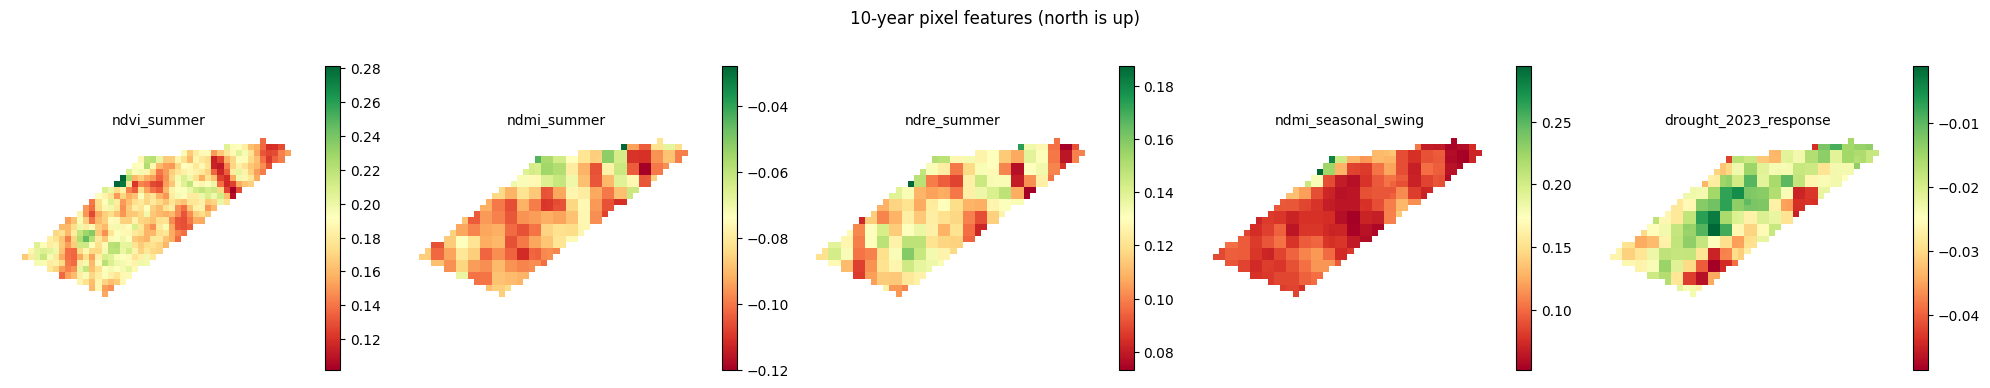

In [ ]:
inner = df[df.inner].copy()
feat = compute_features(inner, years)
n_before = len(feat)
feat = feat.dropna()
inner = inner.loc[feat.index]
print(f"{len(feat)} pixels with complete history ({n_before - len(feat)} dropped for missing data)")
display(feat.describe().round(3))

fig, axes = plt.subplots(1, len(feat.columns), figsize=(4 * len(feat.columns), 4))
for ax, colname in zip(axes, feat.columns):
    g = np.full(grid_shape, np.nan)
    g[inner.row.values, inner.col.values] = feat[colname].values
    im = ax.imshow(g, cmap="RdYlGn"); ax.set_title(colname, fontsize=10); ax.axis("off")
    plt.colorbar(im, ax=ax, fraction=0.046)
plt.suptitle("10-year pixel features (north is up)"); plt.tight_layout(); plt.show()

## 6. Choosing the number of zones (K)
K-means on standardized features, scored with the silhouette coefficient.

In [ ]:
results = choose_clusters(feat, K_CANDIDATES)
for k, r in results.items():
    s = r["silhouette"]
    verdict = "clear" if s > 0.5 else ("moderate" if s >= 0.25 else "weak")
    sizes = np.bincount(r["labels"]).tolist()
    print(f"K={k}: silhouette {s:.3f} ({verdict})  | pixels per zone: {list(sizes)}")
print(f"\nExporting K_CHOSEN = {K_CHOSEN}")

K=2: silhouette 0.282 (moderate)  | pixels per zone: [215, 257]
K=3: silhouette 0.311 (moderate)  | pixels per zone: [273, 180, 19]
K=4: silhouette 0.275 (moderate)  | pixels per zone: [19, 148, 153, 152]

Exporting K_CHOSEN = 3


## 7. Zone map
Zones are numbered from driest summer canopy (Z1) to wettest (Z3), then cleaned so they are manageable in the field.

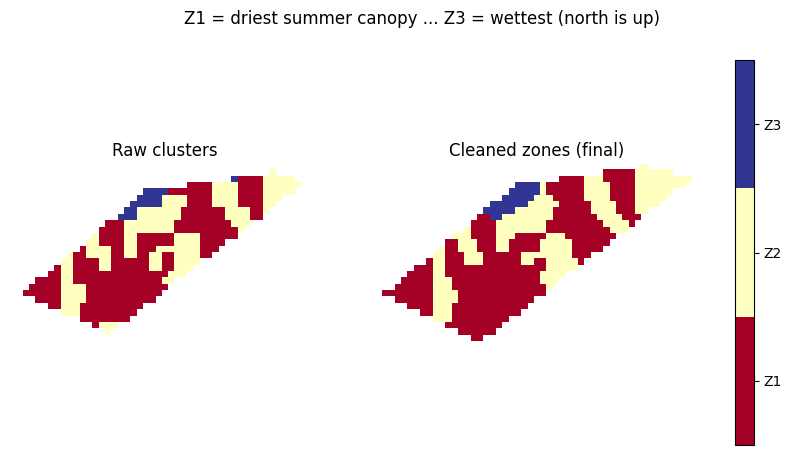

,pixels,ndvi_summer,ndmi_summer,ndre_summer,ndmi_seasonal_swing,drought_2023_response
Z1,284,0.185,-0.096,0.128,0.092,-0.025
Z2,171,0.150,-0.082,0.101,0.074,-0.019
Z3,17,0.213,-0.063,0.138,0.189,-0.026


In [ ]:
raw_labels = order_labels(results[K_CHOSEN]["labels"], feat["ndmi_summer"])   # Z1 = driest summer canopy
g_raw = labels_to_grid(inner, raw_labels, grid_shape)
g_clean = merge_small_fragments(majority_filter(g_raw, K_CHOSEN), K_CHOSEN, MIN_FRAGMENT_PIXELS)
farm_mask = np.zeros(grid_shape, bool); farm_mask[df.row.values, df.col.values] = True
g_final = fill_edge_pixels(g_clean, farm_mask)
final_labels = g_final[inner.row.values, inner.col.values]

cmap = plt.get_cmap("RdYlBu", K_CHOSEN)
fig, axes = plt.subplots(1, 2, figsize=(11, 5))
for ax, g, title in [(axes[0], g_raw, "Raw clusters"), (axes[1], g_final, "Cleaned zones (final)")]:
    show = np.where(g > 0, g, np.nan)
    im = ax.imshow(show, cmap=cmap, vmin=0.5, vmax=K_CHOSEN + 0.5); ax.set_title(title); ax.axis("off")
cb = plt.colorbar(im, ax=axes, ticks=range(1, K_CHOSEN + 1)); cb.set_ticklabels([f"Z{i}" for i in range(1, K_CHOSEN + 1)])
plt.suptitle("Z1 = driest summer canopy ... Z%d = wettest (north is up)" % K_CHOSEN); plt.show()

zone_table = feat.assign(zone=final_labels).groupby("zone").mean().round(3)
zone_table.insert(0, "pixels", pd.Series(final_labels).value_counts().sort_index().values)
zone_table.index = [f"Z{i}" for i in zone_table.index]
display(zone_table)

## 8. Are the zones stable over time?
If the zone ranking holds every year, the zones reflect permanent properties of the farm rather than one season's weather.

Summer NDMI by zone and year:


,Z1,Z2,Z3,same_order_as_overall
year,,,,
2017,-0.065,-0.059,-0.043,True
2018,-0.116,-0.098,-0.089,True
2019,-0.087,-0.072,-0.058,True
2020,-0.115,-0.096,-0.069,True
2021,-0.081,-0.075,-0.039,True
2022,-0.111,-0.093,-0.082,True
2023,-0.114,-0.097,-0.085,True
2024,-0.105,-0.089,-0.081,True
2025,-0.080,-0.071,-0.045,True


Summer NDVI by zone and year:


,Z1,Z2,Z3,same_order_as_overall
year,,,,
2017,0.208,0.165,0.232,True
2018,0.165,0.139,0.167,True
2019,0.206,0.161,0.224,True
2020,0.169,0.138,0.195,True
2021,0.195,0.159,0.226,True
2022,0.165,0.135,0.195,True
2023,0.144,0.118,0.185,True
2024,0.169,0.138,0.200,True
2025,0.206,0.166,0.243,True


Zone ranking held in 100% of years (NDMI). Stable zones.


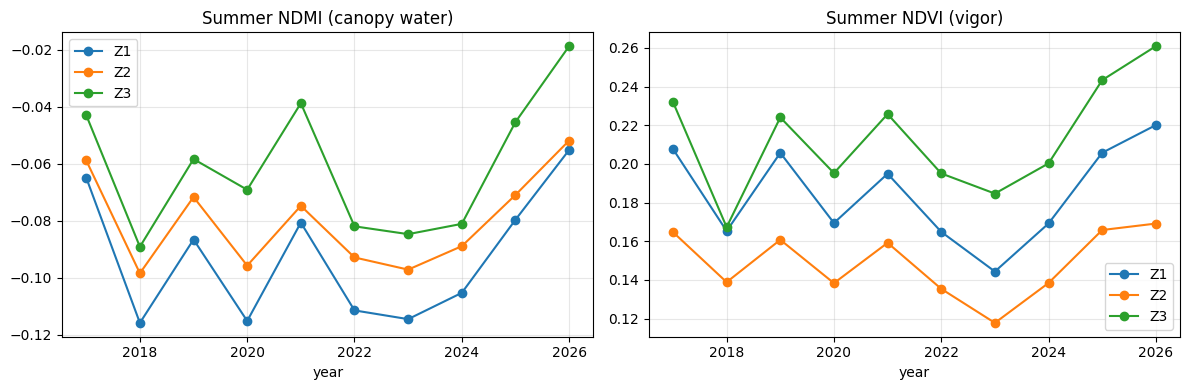

In [ ]:
stab_ndmi = stability_table(inner, final_labels, years, "NDMI")
stab_ndvi = stability_table(inner, final_labels, years, "NDVI")
print("Summer NDMI by zone and year:"); display(stab_ndmi.round(3))
print("Summer NDVI by zone and year:"); display(stab_ndvi.round(3))
share = stab_ndmi["same_order_as_overall"].mean()
print(f"Zone ranking held in {share:.0%} of years (NDMI).",
      "Stable zones." if share >= 0.75 else "Unstable: zones may reflect noise or single-year events — consider fewer zones.")

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, t, name in [(axes[0], stab_ndmi, "Summer NDMI (canopy water)"), (axes[1], stab_ndvi, "Summer NDVI (vigor)")]:
    t.drop(columns="same_order_as_overall").plot(ax=ax, marker="o"); ax.set_title(name); ax.grid(alpha=.3)
plt.tight_layout(); plt.show()

## 9. Export
Zones as GeoJSON polygons and per-pixel table as CSV.

In [ ]:
polys = grid_to_polygons(g_final, df.x.min(), df.y.max(), farm_utm)
props = {int(z[1:]): {k: float(v) for k, v in zone_table.loc[z].items() if k != "pixels"} for z in zone_table.index}
zones = zones_geojson(polys, to_wgs, props)
for f in zones["features"]:
    print(f["properties"]["zone"], f["properties"]["area_ha"], "ha")

with open("dalachi_zones.geojson", "w") as fh: json.dump(zones, fh)
inner.assign(zone=final_labels).to_csv("dalachi_zoning_pixels.csv", index=False)
try:                                   # on Colab, also download the files
    from google.colab import files
    files.download("dalachi_zones.geojson")
    files.download("dalachi_zoning_pixels.csv")
except ImportError:
    print("Saved dalachi_zones.geojson and dalachi_zoning_pixels.csv")

summary = {
    "farm_area_ha": round(farm_utm.area / 10000, 2),
    "pixels_used": int(len(feat)),
    "silhouette": {k: round(r["silhouette"], 3) for k, r in results.items()},
    "k_chosen": K_CHOSEN,
    "zone_area_ha": {f["properties"]["zone"]: f["properties"]["area_ha"] for f in zones["features"]},
    "zone_means": zone_table.drop(columns="pixels").to_dict(orient="index"),
    "ranking_stability_ndmi": round(float(share), 2),
}
print("\n==== Run summary ====")
print(json.dumps(summary, indent=1))

Z1 3.45 ha
Z2 2.12 ha
Z3 0.26 ha



==== Run summary ====
{
 "farm_area_ha": 5.83,
 "pixels_used": 472,
 "silhouette": {
  "2": 0.282,
  "3": 0.311,
  "4": 0.275
 },
 "k_chosen": 3,
 "zone_area_ha": {
  "Z1": 3.45,
  "Z2": 2.12,
  "Z3": 0.26
 },
 "zone_means": {
  "Z1": {
   "ndvi_summer": 0.185,
   "ndmi_summer": -0.096,
   "ndre_summer": 0.128,
   "ndmi_seasonal_swing": 0.092,
   "drought_2023_response": -0.025
  },
  "Z2": {
   "ndvi_summer": 0.15,
   "ndmi_summer": -0.082,
   "ndre_summer": 0.101,
   "ndmi_seasonal_swing": 0.074,
   "drought_2023_response": -0.019
  },
  "Z3": {
   "ndvi_summer": 0.213,
   "ndmi_summer": -0.063,
   "ndre_summer": 0.138,
   "ndmi_seasonal_swing": 0.189,
   "drought_2023_response": -0.026
  }
 },
 "ranking_stability_ndmi": 1.0
}


## 10. Terrain: does the slope explain the zones?
Copernicus 30 m DEM: elevation, slope, aspect (northness/eastness) and topographic position index (TPI; <0 hollow, >0 ridge).

Elevation across the farm: 167 to 195 m

Average terrain per zone:


,eastness,elevation_m,northness,slope_deg,tpi_m
zone,,,,,
Z1,0.11,179.29,0.93,5.54,-0.10
Z2,0.06,175.65,0.79,5.26,0.06
Z3,-0.07,171.35,0.99,3.76,-0.51



How strongly each satellite feature follows the terrain (-1 to +1):


,eastness,elevation_m,northness,slope_deg,tpi_m
ndvi_summer,-0.02,0.17,0.35,0.04,-0.26
ndmi_summer,-0.23,-0.27,-0.27,-0.25,-0.04
ndre_summer,0.05,0.10,0.34,-0.07,-0.23
ndmi_seasonal_swing,-0.13,-0.13,0.17,-0.20,-0.40
drought_2023_response,0.06,-0.27,0.03,-0.07,0.15


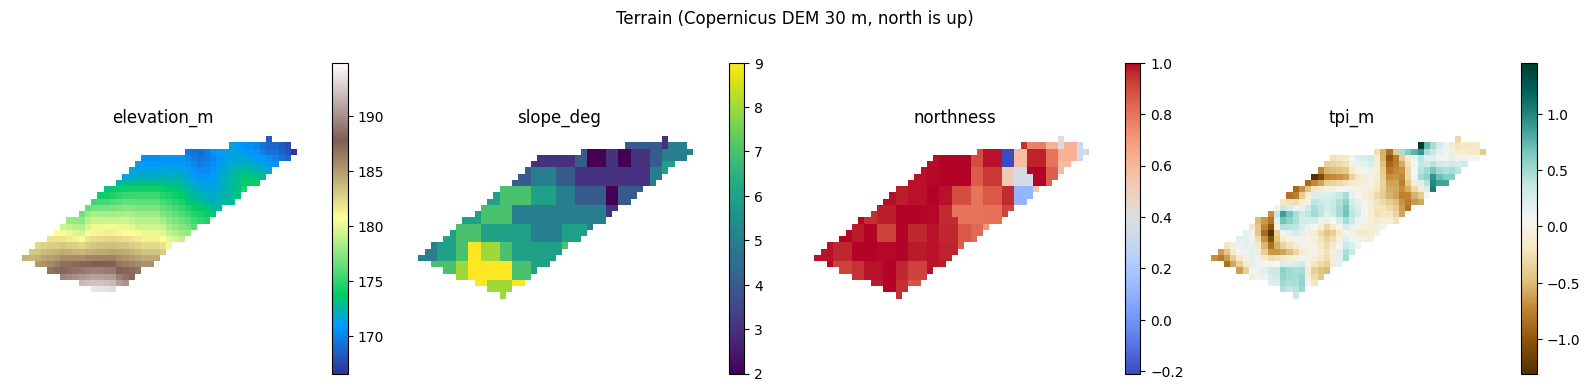

In [ ]:
# Note: COPERNICUS/DEM/GLO30 is deprecated in favour of COPERNICUS/DEM/GLO30_2024_1 (migration pending)
dem = (ee.ImageCollection("COPERNICUS/DEM/GLO30").filterBounds(farm_ee)
       .select("DEM").mosaic().setDefaultProjection("EPSG:4326", None, 30))
dem_b = dem.resample("bilinear")
terr = ee.Terrain.products(dem_b)
asp = terr.select("aspect").multiply(math.pi / 180)
terrain_img = ee.Image.cat([
    dem_b.rename("elevation_m"),
    terr.select("slope").rename("slope_deg"),
    asp.cos().rename("northness"),        # +1 = faces north, -1 = faces south
    asp.sin().rename("eastness"),         # +1 = faces east,  -1 = faces west
    dem_b.subtract(dem_b.focalMean(60, "circle", "meters")).rename("tpi_m"),  # <0 hollow, >0 ridge
])

pts = ee.FeatureCollection([ee.Feature(ee.Geometry.Point([float(lo), float(la)]), {"pid": int(i)})
                            for i, lo, la in zip(inner.index, inner.lon, inner.lat)])
vals = terrain_img.reduceRegions(pts, ee.Reducer.first(), scale=10).getInfo()
terrain = pd.DataFrame([f["properties"] for f in vals["features"]]).set_index("pid").reindex(inner.index)

print(f"Elevation across the farm: {terrain.elevation_m.min():.0f} to {terrain.elevation_m.max():.0f} m")
print("\nAverage terrain per zone:")
display(terrain.assign(zone=[f"Z{int(z)}" for z in final_labels]).groupby("zone").mean().round(2))

corr = pd.concat([feat, terrain], axis=1).corr().loc[feat.columns, terrain.columns].round(2)
print("\nHow strongly each satellite feature follows the terrain (-1 to +1):")
display(corr)

fig, axes = plt.subplots(1, 4, figsize=(16, 4))
for ax, colname, cm in zip(axes, ["elevation_m", "slope_deg", "northness", "tpi_m"],
                           ["terrain", "viridis", "coolwarm", "BrBG"]):
    g = np.full(grid_shape, np.nan)
    g[inner.row.values, inner.col.values] = terrain[colname].values
    im = ax.imshow(g, cmap=cm); ax.set_title(colname); ax.axis("off")
    plt.colorbar(im, ax=ax, fraction=0.046)
plt.suptitle("Terrain (Copernicus DEM 30 m, north is up)"); plt.tight_layout(); plt.show()